# Анализ сигнала акселерометра

Периодичность записи ходьбы и геометрия её окон.

## Импорты и параметры

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import pyshtools as pysh

from statsmodels.tsa.stattools import acf
from visuals import phase_track, plot_phase_track
from my_lib import HankelMatrix, integ, moving_average
from SSA_lib import SSA

try:
    from scipy.special import sph_harm_y
except ImportError:
    from scipy.special import sph_harm

    def sph_harm_y(degree, order, polar, azimuth):
        return sph_harm(order, degree, azimuth, polar)

np.random.seed(42)
pio.renderers.default = 'plotly_mimetype'
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 12})

Matplotlib is building the font cache; this may take a moment.


/Users/rknza/research/D2NN/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Запись ходьбы

In [2]:
start = 7009
n_samples = 459 * 20
sampling_rate = 500

data = pd.read_csv('data/long_walk_100_acc.csv', sep=';', decimal=',')
data = data.iloc[start:start + n_samples].reset_index(drop=True)
t_real = data['time'].to_numpy(dtype=float)
t_real = t_real - t_real[0]
frequency = len(data) / t_real[-1]
assert 480 < frequency < 520

axes = data[['X_value', 'Y_value', 'Z_value']].to_numpy()
x_acc = np.linalg.norm(axes, axis=1)
mean_acceleration = x_acc.mean()
x_acc -= mean_acceleration
t = np.linspace(0, t_real[-1], len(x_acc))

fig = go.Figure(go.Scatter(x=t, y=x_acc, mode='lines', name='Ускорение'))
fig.update_layout(xaxis_title='Время, с', yaxis_title='Ускорение, м/с²')
fig.show()
print(f'{len(x_acc)} отсчётов, {frequency:.2f} Гц')

9180 отсчётов, 500.07 Гц


## Интеграл сигнала

Интеграл модуля ускорения используется как признак, а не как физическая скорость.

In [3]:
t_integral, integral = integ(t, x_acc)
mean_window = 1500
integral_mean = moving_average(integral, mean_window + 1)

## Автокорреляция

In [4]:
acf_values, acf_interval = acf(x_acc, nlags=3000, alpha=0.5, fft=True)
fig = go.Figure(go.Scatter(x=np.arange(len(acf_values)), y=acf_values, name='ACF'))
fig.update_layout(xaxis_title='Сдвиг, отсчёты', yaxis_title='Автокорреляция')
fig.show()

period_samples = 460
T_one_step = period_samples / sampling_rate
print(f'Принятый период: {period_samples} отсчётов = {T_one_step:.2f} с')

/var/folders/g6/5fnjg_911ds0hsfgqdjm4__h0000gn/T/ipykernel_46985/3192000556.py:1: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, acf_interval = acf(x_acc, nlags=3000, alpha=0.5, fft=True)


Принятый период: 460 отсчётов = 0.92 с


## SSA и PCA

Восстанавливаем сигнал по первым 4–5 компонентам SSA и строим траектории окон.

In [5]:
accel_ssa = SSA(x_acc, 500, n_components=30)

In [6]:
n_fig = 1000
fig = go.Figure()
fig.add_scatter(x=t[:n_fig], y=x_acc[:n_fig], mode='lines', name='Исходный сигнал')
fig.add_scatter(x=t[:n_fig], y=accel_ssa.reconstruct(slice(0, 5))[:n_fig],
                mode='lines', name='SSA: 5 компонент')
fig.update_layout(xaxis_title='Время, с', yaxis_title='Ускорение, м/с²')
fig.show()

In [7]:
x_acc_clear = accel_ssa.reconstruct(slice(0, 5)).to_numpy()

In [8]:
track1, basis1 = phase_track(x_acc_clear[:, None], 300, 2)
track2, basis2 = phase_track(x_acc_clear[:, None], 300, 3)
plot_phase_track(track2)

Explained variation for 2 principal components: [0.43823261 0.38093902]
Cumulative explained variationfor 2 principal components: 0.8191716282308463

Explained variation for 3 principal components: [0.43823261 0.38093902 0.0992254 ]
Cumulative explained variationfor 3 principal components: 0.918397028395542



In [9]:
singular_raw = np.linalg.svd(HankelMatrix(x_acc, 600), compute_uv=False)
singular_ssa = np.linalg.svd(HankelMatrix(x_acc_clear, 600), compute_uv=False)
track5, basis5 = phase_track(x_acc_clear[:, None], 600, 4)

Explained variation for 4 principal components: [0.40007959 0.36765125 0.11354118 0.1132465 ]
Cumulative explained variationfor 4 principal components: 0.9945185125811862



## Сфера и разброс траектории

In [10]:
track_centered = track2 - track2.mean(axis=0)
track_norm = track_centered / np.linalg.norm(track_centered, axis=1, keepdims=True)
n_cycles = 15
cycle_length = 461
track_mean = track_norm[:n_cycles * cycle_length].reshape(n_cycles, cycle_length, 3).mean(axis=0)

def to_spherical(track):
    phi = np.arctan2(track[:, 1], track[:, 0]) + np.pi
    theta = np.arccos(np.clip(track[:, 2], -1, 1))
    return phi, theta

phi, theta = to_spherical(track_norm)
phi_mean, theta_mean = to_spherical(track_mean)
theta_cycles = theta[:n_cycles * cycle_length].reshape(n_cycles, cycle_length)
theta_std = np.sqrt(np.sum((theta_cycles - theta_mean) ** 2, axis=0) / (n_cycles - 1))


## Сферические гармоники

Угловую траекторию записываем на сетке 128×128 и раскладываем по сферическим гармоникам.

In [11]:
def sph_sample(n):
    j = np.arange(n)
    return np.pi * j / n, 2 * np.pi * j / n


def sph_harm_transform(values):
    n = values.shape[0]
    assert values.shape == (n, n) and np.log2(n).is_integer()
    phi, theta = np.meshgrid(*sph_sample(n))
    indices = np.arange(n)
    l = np.arange(n // 2)
    weights = np.array([
        2 * np.sqrt(2) / n * np.sin(np.pi * j / n)
        * np.sum(np.sin((2 * l + 1) * np.pi * j / n) / (2 * l + 1))
        for j in indices
    ])
    weighted_values = values * weights[None, :]
    factor = 2 * np.sqrt(np.pi) * np.sqrt(2 * np.pi) / n
    coefficients = []
    for degree in range(n // 2):
        row = []
        for order in range(-degree, degree + 1):
            harmonic = sph_harm_y(degree, order, phi, theta)
            row.append(np.sum(factor * weighted_values * np.conj(harmonic)))
        coefficients.append(row)
    return coefficients


def sph_harm_to_shtools(coefficients):
    n = len(coefficients)
    result = np.zeros((2, n, n), dtype=complex)
    for degree, row in enumerate(coefficients):
        row = np.asarray(row)
        result[0, degree, :degree + 1] = row[degree:]
        result[1, degree, 1:degree + 1] = row[:degree][::-1]
    return result

n_grid = 128
angular_image = np.zeros((n_grid, n_grid))
angle_time = np.linspace(0, 2, cycle_length)
for column in range(n_grid):
    for offset in (0, 1):
        value = np.interp(offset + column / n_grid, angle_time, theta_mean / np.pi)
        row = np.clip(int(value * n_grid), 0, n_grid - 1)
        angular_image[row, column] = 1000


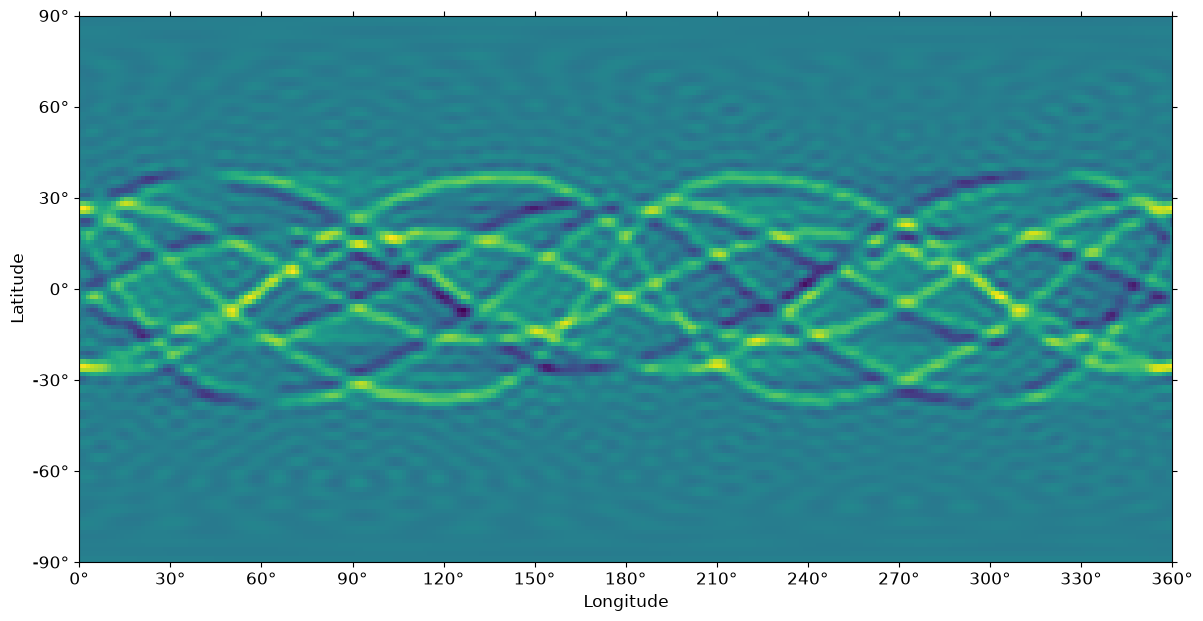

In [12]:
coefficients = sph_harm_to_shtools(sph_harm_transform(angular_image.T))
sh_model = pysh.SHCoeffs.from_array(np.real(coefficients))
sh_grid = sh_model.expand()
fig, ax = sh_grid.plot(show=False)
plt.show()

## Directional regression

Аппроксимируем радиус траектории по преобразованным угловым координатам.

In [13]:
def trajectory_to_spherical(trajectory):
    radius = np.linalg.norm(trajectory, axis=1)
    angle1 = np.arccos(np.clip(trajectory[:, 0] / radius, -1, 1))
    angle2 = np.mod(np.arctan2(trajectory[:, 2], trajectory[:, 1]), 2 * np.pi)
    return np.column_stack([angle1, angle2, radius])


def trajectory_to_cartesian(trajectory):
    angle1, angle2, radius = trajectory.T
    return np.column_stack([radius * np.cos(angle1),
                            radius * np.sin(angle1) * np.cos(angle2),
                            radius * np.sin(angle1) * np.sin(angle2)])


def directional_regression(features, target, n_bins=30, n_components=2):
    covariance = np.cov(features.T)
    values, vectors = np.linalg.eigh(covariance)
    whitening = (vectors * values ** -0.5) @ vectors.T
    standardized = (features - features.mean(axis=0)) @ whitening
    edges = np.histogram_bin_edges(target, bins=n_bins)
    bins = np.clip(np.digitize(target, edges) - 1, 0, n_bins - 1)
    n_features = features.shape[1]
    matrix1 = np.zeros((n_features, n_features))
    matrix2 = np.zeros_like(matrix1)
    for index in range(n_bins):
        group = standardized[bins == index]
        if len(group) < 2:
            raise ValueError(f'В интервале {index} недостаточно точек для ковариации')
        probability = len(group) / len(features)
        mean = group.mean(axis=0)
        outer = np.outer(mean, mean)
        moment = np.cov(group.T) + outer
        matrix1 += probability * moment @ moment
        matrix2 += probability * outer
    matrix = (2 * matrix1 + 2 * matrix2 @ matrix2
              + 2 * np.trace(matrix2) * matrix2 - 2 * np.eye(n_features))
    values, vectors = np.linalg.eigh(matrix)
    directions = vectors[:, np.argsort(values)[::-1][:n_components]]
    return features @ directions


def add_intercept(features):
    return np.column_stack([features, np.ones(len(features))])

normalized_signal = (x_acc - x_acc.mean()) / x_acc.std()
track_dr, basis_dr = phase_track(normalized_signal[:, None], 600, 3)
spherical = trajectory_to_spherical(track_dr)
predicted_angles = directional_regression(spherical[:, :2], spherical[:, 2])
design = add_intercept(predicted_angles)
radius_model, _, _, _ = np.linalg.lstsq(design, spherical[:, 2], rcond=None)
dr_spherical = spherical.copy()
dr_spherical[:, 2] = design @ radius_model
dr_trajectory = trajectory_to_cartesian(dr_spherical)

Explained variation for 3 principal components: [0.27454335 0.25188534 0.07913428]
Cumulative explained variationfor 3 principal components: 0.6055629735078875



In [14]:
fig = go.Figure()
for trajectory, name in [(track_dr, 'Исходная траектория'), (dr_trajectory, 'Directional regression')]:
    fig.add_trace(go.Scatter3d(x=trajectory[:, 0], y=trajectory[:, 1], z=trajectory[:, 2],
                               mode='markers', marker={'size': 2}, name=name))
fig.show()